# 10 · Exploratory visual information at HARV and CPER (processed RGB)

**Status: exploratory** (review 3). These are the first comparisons of context-only and context-plus-visual predictive models on real images, for two sites and one summer. They are not confirmatory Exp 2a. NEON imagery permits processed-RGB prediction feasibility only, with no extinction, contrast-decay or hygroscopicity claims.

**Analysis plan, written before this notebook was first executed.**

| element | choice |
|---|---|
| rows | hourly frames (06–19 LST) with a valid label and SW > 10 W m⁻² (notebook 09) |
| label | `D_h = T_asp − Td_probe` (K); label and conditioning temperature share the aspirated unit, declared with `allow_shared_sensor=True` |
| context C | hour Fourier basis (2 harmonics), cubic spline in T_asp (fixed knots), T_asp × hour basis, day-of-year spline, plus a train-only projection E[V \| hour, T, doy] per visual column |
| visual V | the nine predefined features of `features.py`, minus the two sky features where the notebook 09 image-QC rule drops them |
| model | ridge with day-grouped tuning, robust Gaussian score (1 % Cauchy), common support on (hour, T) |
| Q0 | cyclic-shift refitting permutation test, shifts ≥ 7 days, contiguous 16-day folds, 3-day purge; the number of shifts and the attainable minimum p are reported |
| G | chronological hold-out, first 60 % of days fit, 2-day purge, rest evaluated; week-cluster interval reported as **indicative** with the number of evaluation weeks |
| sensitivities | probe-temperature label `D_probe`; dew point as target (information-equivalent at fixed T_asp); RH ≥ 98.3 % stratum excluded; acquisition-only control (auto-exposure in place of V); single features |
| decision | none; results go to independent review |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from visual_hygrometry import data, features, inference, policy, scoring, splits, worlds

plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (11, 3.2), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.precision', 4)
SITES = {'HARV': -5, 'CPER': -7}
KNOTS, DOY_KNOTS = np.arange(-4, 45, 4.0), np.arange(140, 260.1, 15.0)
T = {site: pd.read_csv(data.ROOT / 'data' / 'interim' / f'm1_{site}.csv', parse_dates=['utc', 'minute', 'day']) for site in SITES}
VIS = {site: [n for n in features.NAMES if not (t.qc_sky_clip.median() > .2 and n.startswith('vis_sky'))] for site, t in T.items()}
print({site: (len(t), t.day.nunique(), VIS[site]) for site, t in T.items()})


def build(site, label='D_h'):
    t, off = T[site], SITES[site]
    df = t.assign(temp_cond_c=t.t_asp, hour_local=(t.utc.dt.hour + t.utc.dt.minute / 60 + off) % 24, doy=t.day.dt.day_of_year, d_ref_k=t[label] if label != 'td' else np.nan,
                  td_ref_c=t.td, calib_exposure=t.exposure, ref_sensor_id='TRAAT' if label == 'D_h' else 'HMP155', cond_sensor_id='TRAAT')
    df = pd.concat([df, data.fourier(df.hour_local, 24, 2, 'hour'), data.spline(df.doy, DOY_KNOTS, 'doy_spl')], axis=1)
    df, ctx = worlds.add_context_basis(df, KNOTS)
    return df, ctx + [c for c in df if c.startswith('doy_spl')], (df.day - df.day.min()).dt.days.to_numpy()


def analyse(site, label='D_h', vis=None, level='e2', rows=None, full=True, proj=(slice(None), 1)):
    """proj: (columns of (hour, T, doy) the visual projection uses, days per inner projection group); declared (all, 1)."""
    df, ctx, g = build(site, label)
    if rows is not None:
        m = rows(df).to_numpy()
        df, g = df[m].reset_index(drop=True), g[m]
    target = 'td_ref_c' if label == 'td' else 'd_ref_k'
    Xc, Xvc, y, _ = policy.select_sci(df, level, ctx, vis or VIS[site], target=target, allow_shared_sensor=label == 'D_h')
    C0, V, y = Xc.to_numpy(), Xvc.to_numpy()[:, Xc.shape[1]:], y.to_numpy()
    raw, (cols, blk) = df[['hour_local', 'temp_cond_c', 'doy']].to_numpy(), proj
    tt = pd.Series(pd.to_datetime(g, unit='D'))
    sp = splits.kfold(splits.assign_folds(g // 16, 5, 'contiguous'), tt, tt, embargo='3D')
    C = [np.c_[C0, p] for p in inference.project_splits(raw[:, cols], V, sp, g // blk)]
    keep = scoring.support_mask(raw[:, :2], sp)
    r = scoring.contrast(C, [np.c_[c, V] for c in C], y, sp, g, keep=keep, robust=True)
    out = dict(site=site, label=label, n_vis=V.shape[1], rows=int(keep.sum()), days=len(np.unique(g)), cross_fit=r.mean, excluded=1 - keep.mean())
    if not full: return out
    _, p, null = inference.perm_test(C, V, y, sp, g, df.hour_local.to_numpy(), keep=keep, Cnull=np.c_[C0, inference.project(raw[:, cols], V, g // blk)], shift_min=7, robust=True)
    fit, ev = splits.chrono(g, 0.6, gap=2)
    spc = [(fit, ev)]
    Pc = inference.project_splits(raw[:, cols], V, spc, g // blk)[0]
    rc = scoring.contrast(np.c_[C0, Pc], np.c_[C0, Pc, V], y, spc, g, keep=scoring.support_mask(raw[:, :2], spc), robust=True)
    gg = g[rc.scored]
    lo, hi = inference.cluster_interval(rc.d, gg // 7)
    daily = pd.Series(r.d).groupby(r.groups).mean()
    return out | dict(perm_p=p, n_shifts=len(null), min_attainable_p=1 / (len(null) + 1), null_median=np.median(null), G=rc.mean, G_lo=lo, G_hi=hi,
                      eval_days=len(np.unique(gg)), eval_weeks=len(np.unique(gg // 7)), score_lag1=daily.autocorr(1), daily_G=pd.Series(rc.d).groupby(gg).mean())

{'HARV': (1197, 92, ['vis_far_contrast', 'vis_near_contrast', 'vis_contrast_ratio', 'vis_far_sat', 'vis_near_gcc', 'vis_near_dark', 'vis_far_sharp']), 'CPER': (1206, 92, ['vis_sky_lum', 'vis_sky_br', 'vis_far_contrast', 'vis_near_contrast', 'vis_contrast_ratio', 'vis_far_sat', 'vis_near_gcc', 'vis_near_dark', 'vis_far_sharp'])}


## 1 · Main analysis

In [2]:
main = pd.DataFrame([analyse(site) for site in SITES]).set_index('site')
main.drop(columns='daily_G')

,label,n_vis,rows,days,cross_fit,excluded,perm_p,n_shifts,min_attainable_p,null_median,G,G_lo,G_hi,eval_days,eval_weeks,score_lag1
site,,,,,,,,,,,,,,,,
HARV,D_h,7,1110,92,-0.5123,0.0727,0.9000,79,0.0125,0.1424,-3.5227,-6.4167,-0.6286,35,6,0.8871
CPER,D_h,9,1172,92,0.1297,0.0282,0.5875,79,0.0125,0.1452,0.0705,-0.2295,0.3705,35,6,0.4790


## 2 · Sensitivity analyses

In [3]:
sens = []
for site in SITES:
    sens += [analyse(site, 'D_probe') | {'variant': 'label D_probe'}, analyse(site, 'td') | {'variant': 'target Td (T_asp in context)'},
             analyse(site, rows=lambda d: d.rh_implied < 98.3) | {'variant': 'RH >= 98.3 % stratum excluded'},
             analyse(site, vis=['calib_exposure'], level='e2_acq_control') | {'variant': 'acquisition-only control (exposure)'}]
sens = pd.DataFrame(sens).set_index(['site', 'variant'])
sens[['rows', 'cross_fit', 'perm_p', 'null_median', 'G', 'G_lo', 'G_hi', 'eval_weeks', 'score_lag1']]

rows  cross_fit  perm_p  \
site variant                                                        
HARV label D_probe                        1110    -0.6093  0.9375   
     target Td (T_asp in context)         1110    -0.5819  1.0000   
     RH >= 98.3 % stratum excluded        1097     0.1538  0.5875   
     acquisition-only control (exposure)  1110     0.1496  0.0375   
CPER label D_probe                        1172     0.1400  0.5875   
     target Td (T_asp in context)         1172    -0.0198  0.9375   
     RH >= 98.3 % stratum excluded        1166    -0.4049  1.0000   
     acquisition-only control (exposure)  1172     0.0270  0.0250   

                                          null_median       G    G_lo    G_hi  \
site variant                                                                    
HARV label D_probe                             0.0057  0.2825 -0.0300  0.5951   
     target Td (T_asp in context)              0.0043  0.0448 -0.6532  0.7429   
     RH >= 98.3 % stratum excluded             0.1909  1.0442  0.9159  1.1726   
     acquisition-only control (exposure)       0.0047  0.1311  0.1246  0.1376   
CPER label D_probe                             0.1514  0.0879 -0.2095  0.3853   
     target Td (T_asp in context)              0.1429 -0.0658 -0.4237  0.2920   
     RH >= 98.3 % stratum excluded             0.0119  0.0360 -0.2289  0.3009   
     acquisition-only control (exposure)       0.0025  0.0405  0.0258  0.0552   

                                          eval_weeks  score_lag1  
site variant                                                      
HARV label D_probe                                 6      0.8868  
     target Td (T_asp in context)                  6      0.8842  
     RH >= 98.3 % stratum excluded                 6      0.5163  
     acquisition-only control (exposure)           6      0.5450  
CPER label D_probe                                 6      0.5173  
     target Td (T_asp in context)                  6      0.2442  
     RH >= 98.3 % stratum excluded                 6      0.8805  
     acquisition-only control (exposure)           6      0.3158

In [4]:
single = pd.DataFrame([analyse(site, vis=[n], full=False) | {'feature': n} for site in SITES for n in VIS[site]]).pivot(index='feature', columns='site', values='cross_fit')
single

site,CPER,HARV
feature,,
vis_contrast_ratio,0.0518,0.0298
vis_far_contrast,-0.0100,0.2321
vis_far_sat,-0.1116,0.1348
vis_far_sharp,0.1373,0.0973
vis_near_contrast,0.0754,0.4145
vis_near_dark,0.0538,0.3220
vis_near_gcc,-0.1667,-0.1526
vis_sky_br,0.0247,NaN
vis_sky_lum,0.0173,NaN


## 3 · Post-hoc diagnostics (added after §1–2 were run; not part of the declared plan)

The declared analysis produced a chronological loss of several nats per row at HARV and a positive null median at both sites. The three checks below locate the cause. They are diagnostics, not alternative estimates: choosing among them after seeing their gains would be a forking path.

(a) Daily mean contrast over the evaluation days of the chronological hold-out.

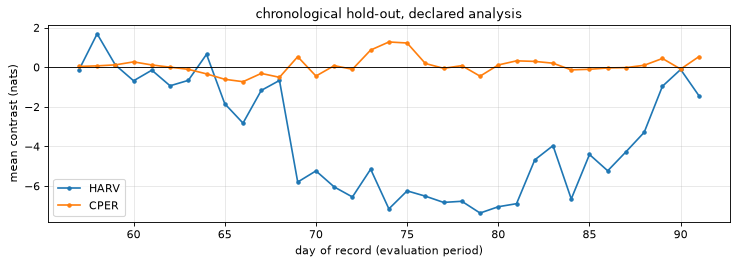

In [5]:
fig, ax = plt.subplots()
for site in SITES: main.loc[site, 'daily_G'].plot(ax=ax, marker='.', label=site)
ax.axhline(0, color='k', lw=.8)
ax.set(xlabel='day of record (evaluation period)', ylabel='mean contrast (nats)', title='chronological hold-out, declared analysis')
ax.legend();

(b) How much of the visual signal the train-only projection carries on fit rows compared with evaluation rows: R² of V by its projection for daily means, median over features.

In [6]:
def carried(site):
    df, ctx, g = build(site)
    V, raw = df[VIS[site]].to_numpy(), df[['hour_local', 'temp_cond_c', 'doy']].to_numpy()
    fit, ev = splits.chrono(g, 0.6, gap=2)
    P = inference.project_splits(raw, V, [(fit, ev)], g)[0]
    r2 = lambda m: np.median([1 - np.var(a - b) / np.var(a) for a, b in zip(pd.DataFrame(V[m]).groupby(g[m]).mean().to_numpy().T, pd.DataFrame(P[m]).groupby(g[m]).mean().to_numpy().T)])
    return dict(fit_rows=r2(fit), eval_rows=r2(ev))

pd.DataFrame({site: carried(site) for site in SITES}).T

,fit_rows,eval_rows
HARV,0.0206,-0.0795
CPER,0.6285,-0.0011


(c) The same analysis with two other projections: inner projection folds of 8-day blocks instead of days, and a projection on (hour, T) only, with season left to the linear day-of-year spline.

In [7]:
VARIANTS = {'declared: (hour, T, doy), day folds': (slice(None), 1), '(hour, T, doy), 8-day folds': (slice(None), 8), '(hour, T) only': (slice(0, 2), 1)}
var = pd.DataFrame([analyse(site, proj=v) | {'projection': k} for site in SITES for k, v in VARIANTS.items()]).set_index(['site', 'projection'])
var[['cross_fit', 'perm_p', 'null_median', 'G', 'G_lo', 'G_hi', 'score_lag1']]

cross_fit  perm_p  null_median  \
site projection                                                            
HARV declared: (hour, T, doy), day folds    -0.5123  0.9000       0.1424   
     (hour, T, doy), 8-day folds             0.2646  0.2500       0.0155   
     (hour, T) only                          0.3172  0.0250       0.0092   
CPER declared: (hour, T, doy), day folds     0.1297  0.5875       0.1452   
     (hour, T, doy), 8-day folds             1.3712  0.0500       0.3441   
     (hour, T) only                          0.1157  0.3500       0.0725   

                                               G     G_lo    G_hi  score_lag1  
site projection                                                                
HARV declared: (hour, T, doy), day folds -3.5227  -6.4167 -0.6286      0.8871  
     (hour, T, doy), 8-day folds         -9.7377 -12.5044 -6.9709      0.3526  
     (hour, T) only                       1.4890   1.1280  1.8500      0.4098  
CPER declared: (hour, T, doy), day folds  0.0705  -0.2295  0.3705      0.4790  
     (hour, T, doy), 8-day folds          0.1661  -0.2355  0.5676      0.7887  
     (hour, T) only                       0.2334  -0.1650  0.6318      0.5203

**Reading. No moisture-information claim is supported.**

*Declared analysis (§1–2).*
- With 92 days and shifts of at least 7 days there are 79 shift configurations, so the minimum attainable p is 0.0125. Neither site rejects (HARV p = 0.90, CPER p = 0.59).
- The chronological G is −3.52 nats at HARV (indicative week-cluster interval −6.42 to −0.63) and +0.07 at CPER (−0.23 to +0.37). Each rests on 35 evaluation days in 6 calendar weeks.
- The daily contrast at HARV is persistent (lag 1 0.89), and the loss is concentrated in three consecutive weeks (plot a). The interval therefore does not describe uncertainty about a stationary G.

*The estimates are not stable under nuisance choices.*
- Excluding the 13 HARV rows in the RH ≥ 98.3 % stratum moves G from −3.5 to +1.04.
- Removing the one CPER frame without `.meta` moved the CPER cross-fit contrast from 0.04 to 0.13 between runs.
- The three projections in §3c give HARV G of −3.5, −9.7 and +1.5 nats.
- No coarse feature set should move a predictive log score by several nats. These swings come from the estimator, not from the images.

*Mechanism.*
- The train-only projection E[V | hour, T, doy] explains 63 % of the daily-mean visual variation on CPER fit rows, where its inner folds interpolate across neighbouring days, but none of it on evaluation rows (§3b).
- The joint model therefore learns a split between projection and image that does not hold out of sample.
- The same interpolation enters the null generator, through the full-sample projection in `Cnull`. Shifted residuals then keep real slow information, which explains null medians of +0.14 nats where a null should sit at or below zero. With the projection on (hour, T) only, the null medians fall to 0.01 (HARV) and 0.07 (CPER).
- At HARV the projection carries almost nothing (R² 0.02). The loss there arises in the joint model itself, and which visual direction drives it has not been isolated.

*Acquisition state is informative.*
- Auto-exposure alone, the acquisition-only control, passes the shift test at both sites (HARV p = 0.0375, CPER p = 0.025), with small positive G (0.13 and 0.04 nats).
- Exposure follows illumination, and illumination (cloudiness) is related to humidity. The current context does not contain it, and the visual features correlate with shortwave up to |r| = 0.65 (notebook 09 §4).

*What this does and does not show.*
- It does not show that the images carry no moisture information.
- It does show that the M0 estimator, validated on synthetic worlds, is not yet reliable on one real season with slow vegetation and weather regimes. It also shows that the context of E2 omits a pathway (illumination) that the images see directly.
- The single-feature table and the (hour, T)-projection variant (HARV p = 0.025, G = +1.49) are post-hoc and must not be read as positive results.
- Open questions for review are in [reviews/m1_exploratory_review.md](../reviews/m1_exploratory_review.md).